# Avance 4.8. Modelos alternativos

Equipo 8 · Cardio AI:

- Clara Janet Rivera Medina A01173512
- José Emiliano Luna López A01551757
- Andre Nicolai Gutierrez Bautista A01793606

En este avance buscamos un modelo individual mejor que el baseline del avance anterior. Probamos siete algoritmos de familias distintas, los comparamos con las mismas particiones y métricas del Avance 3, ajustamos los hiperparámetros de los dos mejores y elegimos el modelo final.

## 1. Configuración y datos de entrada

Partimos de la tabla del Avance 2 (`outputs/avance2_fusion/`). Si no existe, la primera celda ejecuta `Avance2.8.ipynb` para generarla, así que el notebook se puede correr por sí solo con los datos crudos de PTB-XL en `data/raw/ptb-xl/1.0.3`. Limitamos cada proceso a un hilo de cálculo y repartimos el trabajo en paralelo entre pliegues

In [1]:
import os

N_JOBS = min(8, os.cpu_count())
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(variable, "1")

import json
import pickle
import platform
import sys
import time
import warnings
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, PredefinedSplit, RandomizedSearchCV, cross_validate, learning_curve
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT))
from ecg_experiment.intervals import metric_intervals, paired_auroc_difference, patient_groups, patient_resample
from ecg_experiment.paths import to_stored

AVANCE2 = Path(os.environ.get("AVANCE2_OUT", ROOT / "outputs/avance2_fusion"))
OUT = Path(os.environ.get("AVANCE4_OUT", ROOT / "outputs/avance4_modelos_alternativos"))
OUT.mkdir(parents=True, exist_ok=True)
TABLE = AVANCE2 / "ptbxl_caracteristicas_seleccionadas.csv"

if not TABLE.exists():
    import nbformat
    from nbclient import NotebookClient
    print("No está la tabla del Avance 2; se ejecuta Avance2.8.ipynb para generarla (unos 5 minutos).")
    avance2 = nbformat.read(ROOT / "notebooks/Avance2.8.ipynb", as_version=4)
    NotebookClient(avance2, timeout=None, resources={"metadata": {"path": str(ROOT / "notebooks")}}).execute()

SEED = 42
NOTEBOOK_START = time.perf_counter()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind", rc={"figure.dpi": 110, "axes.titlesize": 11})
VERSIONS = {p: version(p) for p in ("numpy", "pandas", "scikit-learn", "seaborn", "matplotlib")}
print(f"Python {platform.python_version()} | " + " | ".join(f"{k} {v}" for k, v in VERSIONS.items()) + f" | {N_JOBS} procesos en paralelo")

Python 3.11.17 | numpy 2.4.6 | pandas 3.0.6 | scikit-learn 1.9.1 | seaborn 0.13.2 | matplotlib 3.11.2 | 8 procesos en paralelo


In [2]:
data = pd.read_csv(TABLE, index_col="ecg_id")
dictionary = pd.read_csv(AVANCE2 / "variables_finales.csv").set_index("variable")
SUPERCLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
METADATA = ["meta_age_group", "meta_sex"]
FEATURES = list(dictionary.index)
assert set(FEATURES) | set(METADATA) | {"patient_id", "strat_fold", "split", "target", *SUPERCLASSES} == set(data.columns)
assert data[FEATURES].notna().all().all()

FAMILY = dictionary.familia
FAMILIES = list(FAMILY.value_counts().index)

X, y = data[FEATURES], data.target.astype(int)
patients, folds = data.patient_id.to_numpy(), data.strat_fold
train, val, test = (data.split == s for s in ("train", "val", "test"))
CV = PredefinedSplit(folds[train].to_numpy())
FOLD_TRAIN, Y_TRAIN, Y_VAL = folds[train].to_numpy(), y[train].to_numpy(), y[val].to_numpy()
PATIENTS_TRAIN, PATIENTS_VAL = patients[train.to_numpy()], patients[val.to_numpy()]

partition = data.groupby("split", sort=False).agg(
    pliegues=("strat_fold", lambda f: f"{f.min()}-{f.max()}" if f.nunique() > 1 else str(f.iloc[0])),
    ECG=("target", "size"), pacientes=("patient_id", "nunique"), cardiopatia_pct=("target", lambda t: 100 * t.mean()),
).loc[["train", "val", "test"]]
display(partition.round(1))
print(f"{len(FEATURES)} características de la señal en {len(FAMILIES)} familias; la edad y el sexo no entran al modelo, igual que en el Avance 3")

,pliegues,ECG,pacientes,cardiopatia_pct
split,,,,
train,1-8,17083,14822,57.6
val,9,2146,1917,57.4
test,10,2158,1877,57.7


111 características de la señal en 8 familias; la edad y el sexo no entran al modelo, igual que en el Avance 3


Hay que recordar que los autores de PTB-XL dividieron los ECG en 10 pliegues, subconjuntos de tamaño parecido, y que cada paciente queda en uno solo. En las tablas de resultados los usamos de dos formas:

- AUROC (VC) y desv. entre pliegues: cada modelo se entrena ocho veces con siete de los pliegues 1 a 8 y se evalúa en el que quedó fuera. La primera columna es el promedio de esos ocho AUROC; la segunda, su desviación estándar, que dice cuánto cambia el resultado según qué ECG le toque evaluar al modelo. Una diferencia entre dos modelos menor que esa desviación no es confiable.
- AUROC pliegue 9: el modelo se entrena una sola vez con los pliegues 1 a 8 y se evalúa en el pliegue 9, que no se usó en ninguna decisión. Confirma que el resultado de la validación cruzada se sostiene en ECG nuevos.

Las demás métricas (sensibilidad, especificidad y AUPRC) se calculan con las predicciones de la validación cruzada. El pliegue 10 queda reservado como prueba y se usa una sola vez, al final.

## 2. Protocolo de comparación elegido

Todos los modelos se comparan con el mismo protocolo del Avance 3:

- Validación cruzada en los ocho pliegues de entrenamiento. Los pliegues de PTB-XL mantienen a cada paciente en uno solo, así que ningún paciente aparece a la vez en el ajuste y en la evaluación.
- Validación. Cada modelo se entrena con los ocho pliegues y se evalúa en el pliegue 9, para confirmar que lo que dice la validación cruzada se sostiene en ECG nuevos.
- Prueba. Se usa una sola vez, al final, con el modelo final ya elegido.

Las métricas son las que definimos en el Avance 3:

| Métrica | Qué mide
| --- | --- |
| AUROC | Probabilidad de que un ECG con cardiopatía reciba una puntuación mayor que uno normal. 0.5 es azar y 1.0 es separación perfecta. |
| Sensibilidad con 90% de especificidad | Fracción de cardiopatías detectadas cuando solo el 10% de los normales se envía a revisión. |
| Especificidad con 95% de sensibilidad | Fracción de normales que no necesitan revisión cuando se detecta el 95% de las cardiopatías. |
| AUPRC | Área bajo la curva de precisión y sensibilidad. |
| Tiempo de entrenamiento y de predicción | Segundos para entrenar con los 17,083 ECG de entrenamiento, y milisegundos para puntuar 1,000 ECG. |

Antes de comparar reproducimos el baseline del Avance 3 con este código.

In [3]:
def specificity_at_sensitivity(y_true, score, target: float = 0.95) -> float:
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(1 - fpr[tpr >= target].min())


def sensitivity_at_specificity(y_true, score, target: float = 0.90) -> float:
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(tpr[fpr <= 1 - target].max())


def summarize(y_true, score) -> dict:
    return {"AUPRC": average_precision_score(y_true, score), "sens_con_esp_90": sensitivity_at_specificity(y_true, score),
            "esp_con_sens_95": specificity_at_sensitivity(y_true, score)}


def scores_of(model, features: pd.DataFrame) -> np.ndarray:
    # Probabilidad si el modelo la entrega; si no, su función de decisión.
    if hasattr(model, "predict_proba"):
        return model.predict_proba(features)[:, 1]
    return model.decision_function(features)


RESULTS = {}


def evaluate(name: str, model) -> dict:
    # Validación cruzada en los pliegues 1-8, y entrenamiento cronometrado con todos ellos para evaluar el pliegue 9.
    cv = cross_validate(model, X[train], y[train], cv=CV, n_jobs=N_JOBS, return_estimator=True, return_indices=True)
    oof = np.empty(len(Y_TRAIN))
    for estimator, rows in zip(cv["estimator"], cv["indices"]["test"]):
        oof[rows] = scores_of(estimator, X[train].iloc[rows])
    per_fold = np.array([roc_auc_score(Y_TRAIN[FOLD_TRAIN == f], oof[FOLD_TRAIN == f]) for f in np.unique(FOLD_TRAIN)])

    start = time.perf_counter()
    fitted = clone(model).fit(X[train], y[train])
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter()
    val_score = scores_of(fitted, X[val])
    predict_ms = 1e6 * (time.perf_counter() - start) / len(val_score)

    RESULTS[name] = {"oof": oof, "per_fold": per_fold, "val": val_score, "model": fitted}
    return {"modelo": name, "AUROC": per_fold.mean(), "AUROC_desv": per_fold.std(), "AUROC_pliegue_9": roc_auc_score(Y_VAL, val_score),
            **summarize(Y_TRAIN, oof), "entrenamiento_s": fit_seconds, "prediccion_ms_por_1000": predict_ms}


baseline_check = evaluate("Regresión logística (baseline)", LogisticRegression(C=0.1, max_iter=5000))
print(f"Baseline del Avance 3 reproducido: AUROC de validación cruzada {baseline_check['AUROC']:.4f} | pliegue 9 {baseline_check['AUROC_pliegue_9']:.4f}")
assert round(baseline_check["AUROC"], 4) == 0.9353 and round(baseline_check["AUROC_pliegue_9"], 3) == 0.928

Baseline del Avance 3 reproducido: AUROC de validación cruzada 0.9353 | pliegue 9 0.9280


## 3. Modelos candidatos

Elegimos siete algoritmos que deciden de formas distintas, para cubrir los principales enfoques de clasificación con datos tabulares:

| Modelo | Familia | Por qué lo probamos |
| --- | --- | --- |
| Regresión logística (baseline) | Lineal discriminativo | Es el baseline del Avance 3 (`C = 0.1`); los demás tienen que superarlo. |
| Análisis discriminante lineal (LDA) | Lineal generativo | Frontera lineal como la logística, pero estimada con otro principio. Dice si importa cómo se estima la frontera. |
| Naive Bayes gaussiano | Probabilístico generativo | Es el modelo más simple y rápido. Muchas de nuestras características están correlacionadas (por ejemplo, la misma medida en varias derivaciones), así que pone a prueba ese supuesto. |
| k vecinos más cercanos (KNN) | Basado en instancias | Captura relaciones no lineales sin suponer ninguna forma. Las características ya están estandarizadas, que es lo que necesita una distancia. |
| Árbol de decisión | Árboles | Es el modelo no lineal más interpretable: un cardiólogo puede seguir sus reglas. |
| Máquina de vectores de soporte (SVM) con kernel RBF | Métodos de kernel | Es de los modelos individuales más fuertes con datos tabulares de tamaño medio, y su capacidad se controla con dos hiperparámetros. |
| Red neuronal (perceptrón multicapa, MLP) | Redes neuronales | Puede aprender interacciones entre características que un modelo lineal no ve. |

En esta primera comparación cada algoritmo usa la configuración por defecto de scikit-learn. Así todos parten en igualdad de condiciones y el ajuste se concentra en los dos mejores. Hay tres excepciones:

- La regresión logística conserva el `C = 0.1` que elegimos en el Avance 3, porque es el baseline que hay que superar.
- La red neuronal usa parada temprana: aparta el 10% de los ECG de entrenamiento y deja de entrenar cuando el desempeño en ese 10% deja de mejorar durante 10 épocas. Sin ella, la configuración por defecto entrena 200 épocas sin vigilar el sobreajuste.
- Los modelos con aleatoriedad (árbol, SVM y red neuronal) usan la semilla 42, para que los resultados sean reproducibles.

In [4]:
CANDIDATES = {
    "Regresión logística (baseline)": LogisticRegression(C=0.1, max_iter=5000),
    "Análisis discriminante lineal": LinearDiscriminantAnalysis(),
    "Naive Bayes gaussiano": GaussianNB(),
    "k vecinos más cercanos": KNeighborsClassifier(),
    "Árbol de decisión": DecisionTreeClassifier(random_state=SEED),
    "SVM con kernel RBF": SVC(random_state=SEED),
    "Red neuronal (MLP)": MLPClassifier(early_stopping=True, max_iter=500, random_state=SEED),
}
display(pd.DataFrame([{"modelo": name, "configuración": repr(model)} for name, model in CANDIDATES.items()]).set_index("modelo"))

,configuración
modelo,
Regresión logística (baseline),"LogisticRegression(C=0.1, max_iter=5000)"
Análisis discriminante lineal,LinearDiscriminantAnalysis()
Naive Bayes gaussiano,GaussianNB()
k vecinos más cercanos,KNeighborsClassifier()
Árbol de decisión,DecisionTreeClassifier(random_state=42)
SVM con kernel RBF,SVC(random_state=42)
Red neuronal (MLP),"MLPClassifier(early_stopping=True, max_iter=50..."


## 4. Comparativa de los modelos

Evaluamos cada modelo con el protocolo que mencionamos en las secciones anteriores y ordenamos la tabla por el AUROC de validación cruzada.

In [5]:
start = time.perf_counter()
comparison = pd.DataFrame([baseline_check] + [evaluate(name, model) for name, model in CANDIDATES.items() if name != "Regresión logística (baseline)"])
comparison = comparison.set_index("modelo").sort_values("AUROC", ascending=False)
comparison.insert(0, "puesto", range(1, len(comparison) + 1))
print(f"Siete modelos evaluados en {time.perf_counter() - start:.0f} s")

COLUMNS = {"puesto": "puesto", "AUROC": "AUROC (VC)", "AUROC_desv": "desv. entre pliegues", "AUROC_pliegue_9": "AUROC pliegue 9",
           "sens_con_esp_90": "sens. con esp. 90%", "esp_con_sens_95": "esp. con sens. 95%", "AUPRC": "AUPRC",
           "entrenamiento_s": "entrenamiento (s)", "prediccion_ms_por_1000": "predicción (ms por 1,000 ECG)"}
DIGITS = {"AUROC (VC)": 4, "desv. entre pliegues": 4, "AUROC pliegue 9": 4, "sens. con esp. 90%": 3, "esp. con sens. 95%": 3, "AUPRC": 3,
          "entrenamiento (s)": 2, "predicción (ms por 1,000 ECG)": 1}
display(comparison[list(COLUMNS)].rename(columns=COLUMNS).round(DIGITS))

Siete modelos evaluados en 31 s


,puesto,AUROC (VC),desv. entre pliegues,AUROC pliegue 9,sens. con esp. 90%,esp. con sens. 95%,AUPRC,entrenamiento (s),"predicción (ms por 1,000 ECG)"
modelo,,,,,,,,,
SVM con kernel RBF,1,0.9509,0.0043,0.9399,0.861,0.712,0.967,3.26,362.2
Red neuronal (MLP),2,0.9484,0.0045,0.9356,0.852,0.689,0.965,0.53,1.0
Regresión logística (baseline),3,0.9353,0.0040,0.9280,0.826,0.620,0.957,0.08,0.8
Análisis discriminante lineal,4,0.9243,0.0047,0.9181,0.798,0.563,0.949,0.09,0.9
Naive Bayes gaussiano,5,0.9150,0.0051,0.9148,0.763,0.559,0.935,0.02,1.1
k vecinos más cercanos,6,0.8989,0.0079,0.8897,0.737,0.000,0.916,0.01,33.1
Árbol de decisión,7,0.8126,0.0126,0.8077,0.000,0.000,0.799,1.76,1.1


La SVM con kernel RBF y la red neuronal son los mejores modelos y los únicos que superan al baseline, en las tres formas de medir: validación cruzada, pliegue 9 y puntos de operación. Su ventaja sobre la regresión logística es varias veces mayor que la variación entre pliegues, así que es real. Entre ellas dos, en cambio, la diferencia es menor que esa variación: con la configuración por defecto no se puede decir cuál es mejor, y por eso pasan juntas al ajuste fino. Las dos trazan fronteras no lineales, lo que concuerda con el subajuste leve del baseline que encontramos en el Avance 3. Los otros cuatro modelos quedan por debajo del baseline. Los ceros del KNN y del árbol de decisión aparecen porque esos modelos dan muy pocas puntuaciones distintas, y sin una escala continua no hay un umbral que alcance esos puntos de operación.

En costo computacional, todos entrenan en segundos con 17,083 ECG. La SVM es la más lenta: 3.26 s para entrenar y 362 ms para puntuar 1,000 ECG, porque cada predicción compara el ECG nuevo con los vectores de soporte.

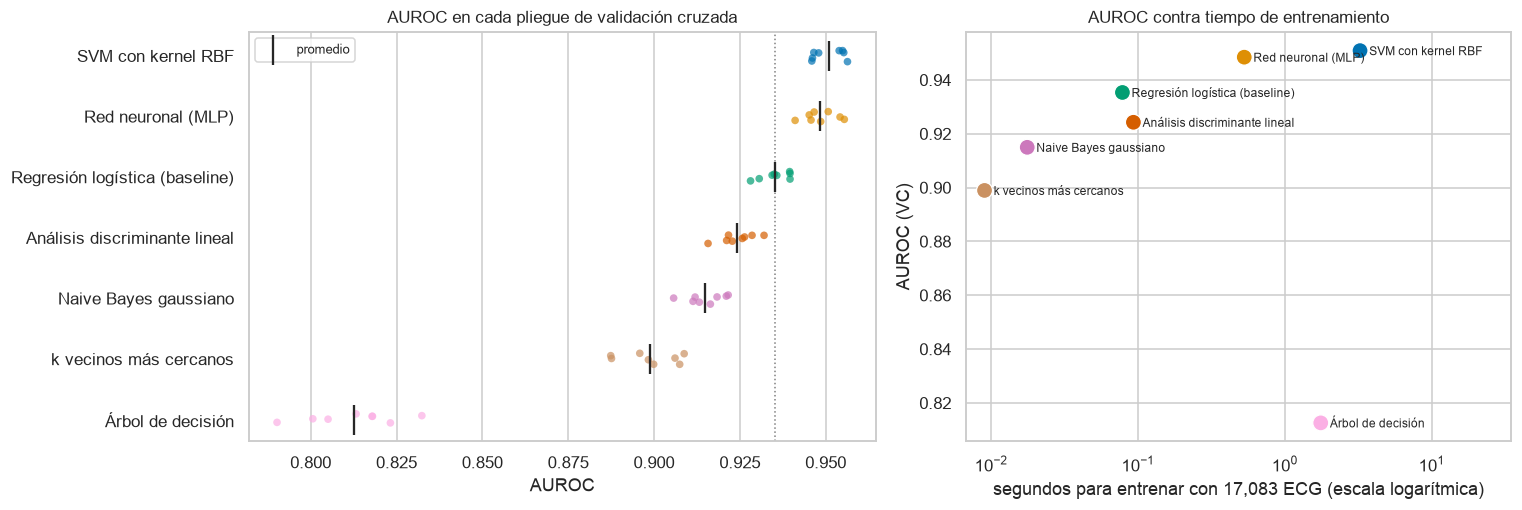

Los dos mejores por AUROC de validación cruzada: SVM con kernel RBF y Red neuronal (MLP)


In [6]:
ORDER = list(comparison.index)
MODEL_COLORS = dict(zip(ORDER, sns.color_palette("colorblind", len(ORDER))))
fold_auroc = pd.DataFrame([{"modelo": name, "pliegue": int(fold), "AUROC": value}
                           for name in ORDER for fold, value in zip(np.unique(FOLD_TRAIN), RESULTS[name]["per_fold"])])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
sns.stripplot(data=fold_auroc, y="modelo", x="AUROC", order=ORDER, hue="modelo", palette=MODEL_COLORS, size=5, alpha=0.7, legend=False, ax=axes[0])
axes[0].scatter(comparison.AUROC, range(len(ORDER)), marker="|", s=400, color="0.15", zorder=3, label="promedio")
axes[0].axvline(comparison.loc["Regresión logística (baseline)", "AUROC"], color="0.5", linestyle=":", linewidth=1)
axes[0].set(title="AUROC en cada pliegue de validación cruzada", ylabel="", xlabel="AUROC")
axes[0].legend(loc="upper left", fontsize=8.5)

sns.scatterplot(data=comparison.reset_index(), x="entrenamiento_s", y="AUROC", hue="modelo", hue_order=ORDER, palette=MODEL_COLORS, s=110, legend=False, ax=axes[1])
for name, row in comparison.iterrows():
    axes[1].annotate(name, (row.entrenamiento_s, row.AUROC), xytext=(6, -3), textcoords="offset points", fontsize=8)
axes[1].set(xscale="log", title="AUROC contra tiempo de entrenamiento", xlabel="segundos para entrenar con 17,083 ECG (escala logarítmica)", ylabel="AUROC (VC)")
axes[1].set_xlim(right=axes[1].get_xlim()[1] * 8)
plt.tight_layout()
plt.show()

TOP_TWO = list(comparison.index[:2])
print("Los dos mejores por AUROC de validación cruzada:", " y ".join(TOP_TWO))

Los ocho pliegues de la SVM y de la red neuronal quedan a la derecha del AUROC promedio del baseline (línea punteada), así que su ventaja no depende de un pliegue en particular. Entre la SVM y la red, en cambio, los pliegues se traslapan: la diferencia entre ellas es pequeña comparada con la variación de un pliegue a otro.

El panel derecho muestra que entrenar más tiempo no garantiza un mejor modelo. El árbol de decisión tarda más que la red neuronal (1.76 s contra 0.53 s) y es el peor. La red está cerca de la esquina ideal, arriba a la izquierda: segunda en AUROC con una sexta parte del tiempo de entrenamiento de la SVM.

Los dos modelos que pasan al ajuste fino son la SVM con kernel RBF y la red neuronal.

Los modelos que quedaron abajo podrían estar en desventaja solo por su configuración por defecto. Antes de quedarnos con los dos primeros, revisamos si alguno de los otros los alcanzaría con un ajuste rápido de su hiperparámetro principal:

- KNN: el número de vecinos `k` y si los vecinos cercanos pesan más que los lejanos.
- Árbol de decisión: la profundidad máxima y el mínimo de ECG por hoja, que limitan cuánto puede memorizar.
- Naive Bayes: `var_smoothing`, que suma una pequeña varianza a todas las características para estabilizar el modelo.
- LDA: la contracción (`shrinkage`) de la matriz de covarianza, útil cuando las características están muy correlacionadas.

La regresión logística ya se ajustó en el Avance 3: su AUROC máximo fue de 0.9365, con `C = 10`.

In [7]:
QUICK_GRIDS = {
    "k vecinos más cercanos": (KNeighborsClassifier(), {"n_neighbors": [5, 15, 31, 61, 121, 241], "weights": ["uniform", "distance"]}),
    "Árbol de decisión": (DecisionTreeClassifier(random_state=SEED), {"max_depth": [4, 6, 8, 10, 15, None], "min_samples_leaf": [1, 10, 50, 100]}),
    "Naive Bayes gaussiano": (GaussianNB(), {"var_smoothing": np.logspace(-9, 0, 10)}),
    "Análisis discriminante lineal": (LinearDiscriminantAnalysis(solver="lsqr"), {"shrinkage": [None, 0.001, 0.01, 0.05, 0.1, 0.3, 0.6]}),
}
quick_rows = []
start = time.perf_counter()
for name, (model, grid) in QUICK_GRIDS.items():
    search = GridSearchCV(model, grid, scoring="roc_auc", cv=CV, n_jobs=N_JOBS, refit=False).fit(X[train], y[train])
    quick_rows.append({"modelo": name, "configuraciones": len(search.cv_results_["params"]), "AUROC por defecto": comparison.loc[name, "AUROC"],
                       "mejor AUROC": search.best_score_, "mejor configuración": search.best_params_})
quick = pd.DataFrame(quick_rows).set_index("modelo")
quick["mejora"] = quick["mejor AUROC"] - quick["AUROC por defecto"]
print(f"Ajuste rápido de {quick.configuraciones.sum()} configuraciones en {time.perf_counter() - start:.0f} s")
display(quick.round(4))
weakest_top = comparison.loc[TOP_TWO, "AUROC"].min()
print(f"AUROC por defecto del segundo lugar: {weakest_top:.4f} | ¿algún otro modelo lo alcanza con el ajuste rápido? {bool((quick['mejor AUROC'] >= weakest_top).any())}")

Ajuste rápido de 53 configuraciones en 90 s


,configuraciones,AUROC por defecto,mejor AUROC,mejor configuración,mejora
modelo,,,,,
k vecinos más cercanos,12,0.8989,0.9311,"{'n_neighbors': 61, 'weights': 'distance'}",0.0322
Árbol de decisión,24,0.8126,0.9244,"{'max_depth': None, 'min_samples_leaf': 100}",0.1118
Naive Bayes gaussiano,10,0.9150,0.9174,{'var_smoothing': 0.1},0.0024
Análisis discriminante lineal,7,0.9243,0.9243,{'shrinkage': 0.001},0.0000


AUROC por defecto del segundo lugar: 0.9484 | ¿algún otro modelo lo alcanza con el ajuste rápido? False


El ajuste rápido de 53 configuraciones cambia mucho a dos modelos. El árbol de decisión sube de 0.813 a 0.924 cuando cada hoja debe tener al menos 100 ECG, lo que le impide memorizar casos individuales. El KNN sube de 0.899 a 0.931 con 61 vecinos ponderados por la distancia. Naive Bayes casi no cambia (0.917) y LDA no mejora (0.924).

Aun así, ninguno alcanza a la red neuronal con su configuración por defecto (0.948), y ninguno supera siquiera al baseline (0.935). Por lo tanto, la selección de los dos mejores no depende de haber usado configuraciones por defecto.

## 5. Ajuste fino de la SVM con kernel RBF

Hacemos la búsqueda en tres etapas, de lo general a lo particular:

1. Kernel: comparamos los cinco kernels con los demás valores por defecto.
2. Búsqueda en malla de `C` y `gamma` con el mejor kernel, en escala logarítmica: seis valores de `C` (0.1 a 30) y cuatro de `gamma` (0.001 a 0.008), 24 combinaciones. Una prueba previa en un solo pliegue mostró que valores de `gamma` más grandes rinden menos y son los más lentos de entrenar, así que la malla se concentra en la zona útil.
3. Malla fina alrededor de la mejor combinación: la mitad y el doble de `C`, y `gamma` multiplicado por 0.7 y 1.4 (nueve combinaciones), y además la mejor combinación con `class_weight="balanced"`.

En todas las etapas guardamos también el AUROC en los datos de entrenamiento. La brecha entre el AUROC de entrenamiento y el de validación cruzada indica qué combinaciones se sobreajustan.

In [8]:
SEARCH_LOG = []


def run_search(model_name: str, stage: str, search):
    start = time.perf_counter()
    search.fit(X[train], y[train])
    table = pd.DataFrame(search.cv_results_)
    SEARCH_LOG.append({"modelo": model_name, "etapa": stage, "configuraciones": len(table), "entrenamientos": len(table) * CV.get_n_splits(),
                       "minutos": (time.perf_counter() - start) / 60, "mejor AUROC (VC)": search.best_score_})
    print(f"{model_name}, {stage}: {len(table)} configuraciones, {len(table) * CV.get_n_splits()} entrenamientos, "
          f"{(time.perf_counter() - start) / 60:.1f} min | mejor AUROC {search.best_score_:.4f} con {search.best_params_}")
    return search, table


def search_cv(model, grid, **kwargs) -> GridSearchCV:
    return GridSearchCV(model, grid, scoring="roc_auc", cv=CV, n_jobs=N_JOBS, refit=False, return_train_score=True, **kwargs)


SVM_BASE = SVC(random_state=SEED)
svm_kernel, svm_kernel_table = run_search("SVM", "1. kernel", search_cv(SVM_BASE, [{"kernel": ["linear", "rbf", "sigmoid"]}, {"kernel": ["poly"], "degree": [2, 3, 4]}]))
svm_kernel_table["kernel"] = [p["kernel"] + (f" (grado {p['degree']})" if "degree" in p else "") for p in svm_kernel_table.params]
display(svm_kernel_table.set_index("kernel")[["mean_train_score", "mean_test_score", "std_test_score", "mean_fit_time"]]
        .rename(columns={"mean_train_score": "AUROC entrenamiento", "mean_test_score": "AUROC (VC)", "std_test_score": "desv. entre pliegues", "mean_fit_time": "segundos por ajuste"})
        .sort_values("AUROC (VC)", ascending=False).round(4))
BEST_KERNEL = svm_kernel.best_params_["kernel"]
print(f"gamma=\"scale\" de la configuración por defecto: 1 / (111 × varianza) = {1 / (len(FEATURES) * X[train].to_numpy().var()):.4f}")

SVM, 1. kernel: 6 configuraciones, 48 entrenamientos, 4.1 min | mejor AUROC 0.9509 con {'kernel': 'rbf'}


,AUROC entrenamiento,AUROC (VC),desv. entre pliegues,segundos por ajuste
kernel,,,,
rbf,0.9695,0.9509,0.0043,11.8216
poly (grado 2),0.9600,0.9459,0.0051,17.1616
poly (grado 3),0.9692,0.9385,0.0045,39.5763
linear,0.9399,0.9363,0.0042,64.3985
poly (grado 4),0.9769,0.9358,0.0052,32.0370
sigmoid,0.8424,0.8420,0.0065,8.4429


gamma="scale" de la configuración por defecto: 1 / (111 × varianza) = 0.0101


El kernel RBF es el mejor (0.9509), así que las siguientes etapas buscan sus mejores valores de `C` y `gamma`.

SVM, 2. malla de C y gamma: 24 configuraciones, 192 entrenamientos, 20.8 min | mejor AUROC 0.9509 con {'C': 3, 'gamma': 0.008}


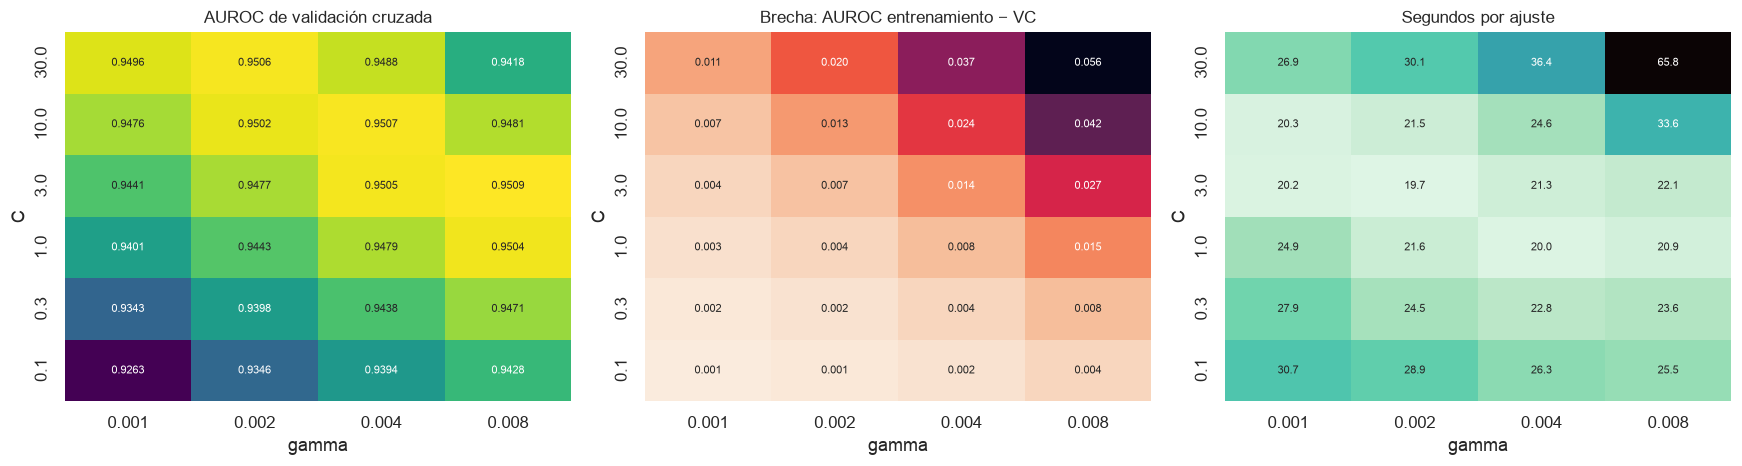

In [9]:
C_GRID = [0.1, 0.3, 1, 3, 10, 30]
GAMMA_GRID = [0.001, 0.002, 0.004, 0.008]
svm_grid, svm_grid_table = run_search("SVM", "2. malla de C y gamma", search_cv(SVM_BASE.set_params(kernel=BEST_KERNEL), {"C": C_GRID, "gamma": GAMMA_GRID}))
svm_grid_table["C"], svm_grid_table["gamma"] = svm_grid_table.param_C.astype(float), svm_grid_table.param_gamma.astype(float)
svm_grid_table["brecha"] = svm_grid_table.mean_train_score - svm_grid_table.mean_test_score

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
panels = [("mean_test_score", "AUROC de validación cruzada", "viridis", ".4f"), ("brecha", "Brecha: AUROC entrenamiento − VC", "rocket_r", ".3f"),
          ("mean_fit_time", "Segundos por ajuste", "mako_r", ".1f")]
for ax, (column, title, cmap, fmt) in zip(axes, panels):
    sns.heatmap(svm_grid_table.pivot(index="C", columns="gamma", values=column).sort_index(ascending=False), annot=True, fmt=fmt, cmap=cmap,
                annot_kws={"fontsize": 7.5}, cbar=False, ax=ax)
    ax.set(title=title, xlabel="gamma", ylabel="C")
plt.tight_layout()
plt.show()

Cada mapa responde una pregunta:

- AUROC de validación cruzada: ¿qué combinación es mejor? Hay una franja diagonal de combinaciones casi equivalentes, todas entre 0.950 y 0.951. La mejor es `C = 3` con `gamma = 0.008`.
- Brecha: ¿dónde se sobreajusta el modelo? Arriba a la derecha, con `C` y `gamma` altos, la brecha entre entrenamiento y validación cruzada llega a 0.056. Abajo a la izquierda casi no hay brecha, pero el AUROC baja a 0.926: es subajuste.
- Segundos por ajuste: ¿cuánto cuesta? La esquina que más se sobreajusta es también la más lenta.

La configuración por defecto (`C = 1` y `gamma` de 0.010) ya estaba dentro de la franja óptima, así que el ajuste no puede mejorar mucho a la SVM.

In [10]:
best_C, best_gamma = svm_grid.best_params_["C"], svm_grid.best_params_["gamma"]
fine_grid = [{"C": [round(best_C * f, 4) for f in (0.5, 1, 2)], "gamma": [round(best_gamma * f, 6) for f in (0.7, 1, 1.4)]},
             {"C": [best_C], "gamma": [best_gamma], "class_weight": ["balanced"]}]
svm_fine, svm_fine_table = run_search("SVM", "3. malla fina", search_cv(SVM_BASE.set_params(kernel=BEST_KERNEL), fine_grid))
svm_fine_table["class_weight"] = svm_fine_table.param_class_weight.fillna("ninguno").astype(str)
display(svm_fine_table.sort_values("mean_test_score", ascending=False).head(8)[["param_C", "param_gamma", "class_weight", "mean_train_score", "mean_test_score", "std_test_score"]]
        .rename(columns={"param_C": "C", "param_gamma": "gamma", "mean_train_score": "AUROC entrenamiento", "mean_test_score": "AUROC (VC)", "std_test_score": "desv. entre pliegues"}).round(4))
print(f"Rango del AUROC (VC) en la malla fina: {svm_fine_table.mean_test_score.min():.4f} a {svm_fine_table.mean_test_score.max():.4f} | configuración por defecto: {comparison.loc['SVM con kernel RBF', 'AUROC']:.4f}")

SVM_PARAMS = {"kernel": BEST_KERNEL, **svm_fine.best_params_}
SVM_TUNED = SVC(random_state=SEED, **SVM_PARAMS)
print("Configuración final de la SVM:", SVM_PARAMS)

SVM, 3. malla fina: 10 configuraciones, 80 entrenamientos, 8.5 min | mejor AUROC 0.9511 con {'C': 3, 'gamma': 0.0056}


,C,gamma,class_weight,AUROC entrenamiento,AUROC (VC),desv. entre pliegues
3,3.0,0.0056,ninguno,0.9700,0.9511,0.0044
1,1.5,0.0080,ninguno,0.9696,0.9510,0.0044
2,1.5,0.0112,ninguno,0.9767,0.9510,0.0045
4,3.0,0.0080,ninguno,0.9776,0.9509,0.0046
9,3.0,0.0080,balanced,0.9775,0.9508,0.0045
6,6.0,0.0056,ninguno,0.9771,0.9507,0.0046
0,1.5,0.0056,ninguno,0.9634,0.9503,0.0041
5,3.0,0.0112,ninguno,0.9855,0.9499,0.0047


Rango del AUROC (VC) en la malla fina: 0.9477 a 0.9511 | configuración por defecto: 0.9509
Configuración final de la SVM: {'kernel': 'rbf', 'C': 3, 'gamma': 0.0056}


La malla fina confirma que no hay nada mejor cerca. La SVM ya estaba en su óptimo.

## 6. Ajuste fino de la red neuronal (MLP)

Ajustamos cinco hiperparámetros:

- Arquitectura: de 1 a 3 capas ocultas, con 32 a 512 neuronas por capa.
- Función de activación: ReLU, `tanh` o logística.
- Tasa de aprendizaje: el tamaño de cada paso del entrenamiento.
- `alpha`: la regularización L2 de los pesos, que frena el sobreajuste.
- Tamaño del lote: cuántos ECG se usan en cada paso.

Son demasiados para una malla completa, así que la búsqueda tiene tres etapas: una búsqueda aleatoria de 60 configuraciones, un refinamiento alrededor de la mejor y una prueba con 5 semillas para medir cuánto cambia el resultado por el azar de la inicialización.

In [11]:
ARCHITECTURES = [(32,), (64,), (128,), (256,), (512,), (64, 32), (128, 64), (128, 128), (256, 128), (256, 256), (512, 256),
                 (128, 64, 32), (256, 128, 64), (256, 256, 256)]
MLP_SPACE = {"hidden_layer_sizes": ARCHITECTURES, "activation": ["relu", "tanh", "logistic"], "alpha": loguniform(1e-5, 1),
             "learning_rate_init": loguniform(1e-4, 3e-2), "batch_size": [32, 64, 128, 256, 512]}
MLP_BASE = MLPClassifier(early_stopping=True, max_iter=500, random_state=SEED)
mlp_random, mlp_random_table = run_search("Red neuronal", "1. búsqueda aleatoria", RandomizedSearchCV(
    MLP_BASE, MLP_SPACE, n_iter=60, scoring="roc_auc", cv=CV, n_jobs=N_JOBS, refit=False, return_train_score=True, random_state=SEED))


def describe_mlp(table: pd.DataFrame) -> pd.DataFrame:
    table = table.copy()
    table["arquitectura"] = table.param_hidden_layer_sizes.map(lambda t: "-".join(map(str, t)))
    table["capas"] = table.param_hidden_layer_sizes.map(len)
    table["activación"] = table.param_activation
    table["brecha"] = table.mean_train_score - table.mean_test_score
    return table


mlp_random_table = describe_mlp(mlp_random_table)
MLP_SHOW = {"arquitectura": "arquitectura", "activación": "activación", "param_alpha": "alpha", "param_learning_rate_init": "tasa de aprendizaje",
            "param_batch_size": "lote", "mean_train_score": "AUROC entrenamiento", "mean_test_score": "AUROC (VC)", "std_test_score": "desv. entre pliegues"}
display(mlp_random_table.sort_values("mean_test_score", ascending=False).head(10)[list(MLP_SHOW)].rename(columns=MLP_SHOW).round(5).reset_index(drop=True))

Red neuronal, 1. búsqueda aleatoria: 60 configuraciones, 480 entrenamientos, 10.1 min | mejor AUROC 0.9490 con {'activation': 'relu', 'alpha': np.float64(3.692900498700231e-05), 'batch_size': 64, 'hidden_layer_sizes': (128,), 'learning_rate_init': np.float64(0.0003682528501021884)}


,arquitectura,activación,alpha,tasa de aprendizaje,lote,AUROC entrenamiento,AUROC (VC),desv. entre pliegues
0,128,relu,0.00004,0.00037,64,0.96885,0.94903,0.00392
1,256,relu,0.00001,0.00081,512,0.96616,0.94892,0.00398
2,256-128-64,relu,0.00025,0.00022,256,0.97498,0.94842,0.00402
3,128-128,relu,0.02849,0.00022,64,0.97086,0.94792,0.00415
4,128-64,relu,0.00002,0.00026,128,0.96756,0.94787,0.00415
5,128,relu,0.12305,0.00010,32,0.95906,0.94766,0.00403
6,32,relu,0.58258,0.00234,512,0.96229,0.94759,0.00434
7,128,relu,0.00002,0.00025,128,0.96271,0.94740,0.00408
8,256-256-256,relu,0.00006,0.00011,256,0.96977,0.94733,0.00473
9,256,logistic,0.00007,0.00080,32,0.96002,0.94729,0.00332


La tabla muestra las diez mejores configuraciones. La figura siguiente muestra las 60, con una gráfica por hiperparámetro, para ver cuáles importan.

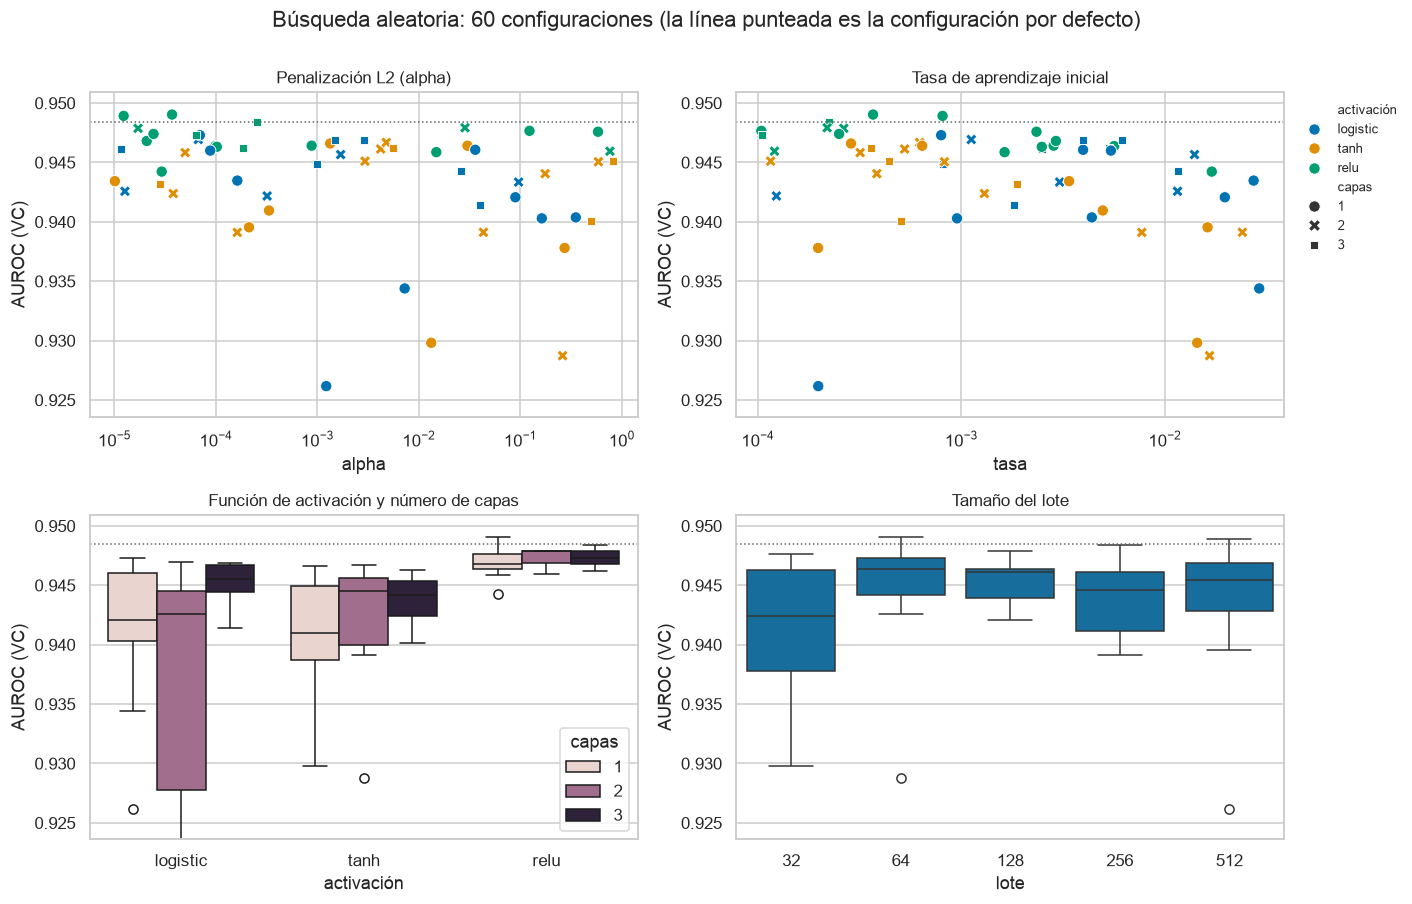

Configuraciones por debajo del eje (AUROC menor que 0.924): 2


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.2))
plot_table = mlp_random_table.assign(alpha=mlp_random_table.param_alpha.astype(float), tasa=mlp_random_table.param_learning_rate_init.astype(float),
                                     lote=mlp_random_table.param_batch_size.astype(int))
floor = plot_table.mean_test_score.quantile(0.05) - 0.005
for ax, column, title, legend in ((axes[0, 0], "alpha", "Penalización L2 (alpha)", False), (axes[0, 1], "tasa", "Tasa de aprendizaje inicial", True)):
    sns.scatterplot(data=plot_table, x=column, y="mean_test_score", hue="activación", style="capas", s=55, legend=legend, ax=ax)
    ax.set(xscale="log", title=title, xlabel=column, ylabel="AUROC (VC)", ylim=(floor, None))
sns.move_legend(axes[0, 1], "upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=8.5)
sns.boxplot(data=plot_table, x="activación", y="mean_test_score", hue="capas", ax=axes[1, 0])
axes[1, 0].set(title="Función de activación y número de capas", ylabel="AUROC (VC)", ylim=(floor, None))
sns.boxplot(data=plot_table, x="lote", y="mean_test_score", color="C0", ax=axes[1, 1])
axes[1, 1].set(title="Tamaño del lote", ylabel="AUROC (VC)", ylim=(floor, None))
for ax in axes.flat:
    ax.axhline(comparison.loc["Red neuronal (MLP)", "AUROC"], color="0.4", linestyle=":", linewidth=1)
plt.suptitle("Búsqueda aleatoria: 60 configuraciones (la línea punteada es la configuración por defecto)", y=1.0)
plt.tight_layout()
plt.show()
print(f"Configuraciones por debajo del eje (AUROC menor que {floor:.3f}): {(plot_table.mean_test_score < floor).sum()}")

De la gráfica concluimos:

- La activación es el que más importa. ReLU da los mejores resultados y los más estables: ninguna de sus configuraciones baja de 0.944.
- Las tasas de aprendizaje mayores que 0.01 y los lotes de 32 ECG empeoran o vuelven inestables los resultados.
- Con ReLU, `alpha` y el número de capas importan poco.

Conclusión: la mejor configuración (una capa de 128 neuronas ReLU) llega a 0.9490, apenas por encima de la configuración por defecto (0.9484, línea punteada).

Red neuronal, 2a. alpha y tasa de aprendizaje: 9 configuraciones, 72 entrenamientos, 0.7 min | mejor AUROC 0.9490 con {'alpha': np.float64(3.692900498700231e-05), 'learning_rate_init': np.float64(0.0003682528501021884)}


Red neuronal, 2b. arquitectura y activación: 27 configuraciones, 216 entrenamientos, 3.9 min | mejor AUROC 0.9490 con {'activation': 'relu', 'hidden_layer_sizes': (128,)}


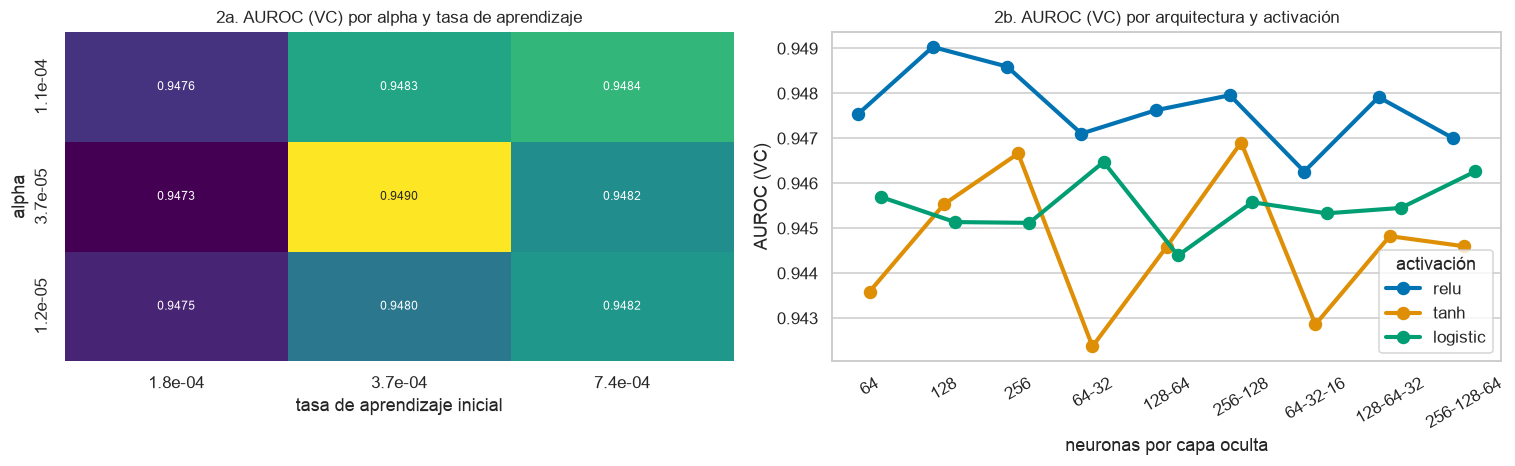

In [13]:
best_random = mlp_random.best_params_
refine_base = clone(MLP_BASE).set_params(hidden_layer_sizes=best_random["hidden_layer_sizes"], activation=best_random["activation"], batch_size=best_random["batch_size"])
refine_grid = {"alpha": [best_random["alpha"] * f for f in (1 / 3, 1, 3)], "learning_rate_init": [best_random["learning_rate_init"] * f for f in (0.5, 1, 2)]}
mlp_refine, mlp_refine_table = run_search("Red neuronal", "2a. alpha y tasa de aprendizaje", search_cv(refine_base, refine_grid))

width, depth = best_random["hidden_layer_sizes"][0], len(best_random["hidden_layer_sizes"])
variants = sorted({tuple(max(16, int(width * scale) // 2 ** i) for i in range(layers)) for layers in (1, 2, 3) for scale in (0.5, 1, 2)}, key=lambda t: (len(t), t))
architecture_base = clone(refine_base).set_params(**mlp_refine.best_params_)
mlp_arch, mlp_arch_table = run_search("Red neuronal", "2b. arquitectura y activación", search_cv(architecture_base, {"hidden_layer_sizes": variants, "activation": ["relu", "tanh", "logistic"]}))
mlp_arch_table = describe_mlp(mlp_arch_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
pivot = mlp_refine_table.assign(alpha=mlp_refine_table.param_alpha.astype(float), tasa=mlp_refine_table.param_learning_rate_init.astype(float)).pivot(
    index="alpha", columns="tasa", values="mean_test_score").sort_index(ascending=False)
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="viridis", cbar=False, annot_kws={"fontsize": 8}, ax=axes[0],
            xticklabels=[f"{v:.1e}" for v in pivot.columns], yticklabels=[f"{v:.1e}" for v in pivot.index])
axes[0].set(title="2a. AUROC (VC) por alpha y tasa de aprendizaje", xlabel="tasa de aprendizaje inicial", ylabel="alpha")
sns.pointplot(data=mlp_arch_table, x="arquitectura", y="mean_test_score", hue="activación", order=["-".join(map(str, v)) for v in variants], dodge=0.3, ax=axes[1])
axes[1].set(title="2b. AUROC (VC) por arquitectura y activación", ylabel="AUROC (VC)", xlabel="neuronas por capa oculta")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

El refinamiento revisa si se gana algo cambiando un poco la mejor configuración. No se gana. Una sola capa de 128 neuronas ReLU es suficiente.

Red neuronal, 3. semillas, por defecto: 5 configuraciones, 40 entrenamientos, 0.2 min | mejor AUROC 0.9488 con {'random_state': 3}


Red neuronal, 3. semillas, ajustada: 5 configuraciones, 40 entrenamientos, 0.3 min | mejor AUROC 0.9494 con {'random_state': 1}


,mean,std,min,max
configuración,,,,
por defecto,0.9482,0.0004,0.9478,0.9488
ajustada,0.9490,0.0004,0.9484,0.9494


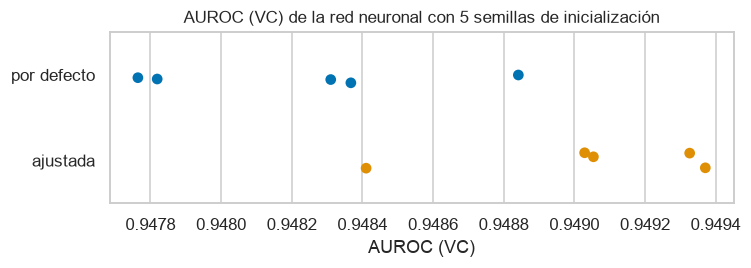

Configuración final de la red neuronal (semilla 42): {'alpha': np.float64(3.7e-05), 'batch_size': 64, 'learning_rate_init': np.float64(0.000368), 'activation': 'relu', 'hidden_layer_sizes': (128,)}


In [14]:
MLP_PARAMS = {**{k: v for k, v in architecture_base.get_params().items() if k in ("alpha", "learning_rate_init", "batch_size")}, **mlp_arch.best_params_}
MLP_TUNED = clone(MLP_BASE).set_params(**MLP_PARAMS)
seed_rows = []
for label, model in (("por defecto", CANDIDATES["Red neuronal (MLP)"]), ("ajustada", MLP_TUNED)):
    _, table = run_search("Red neuronal", f"3. semillas, {label}", search_cv(model, {"random_state": list(range(5))}))
    seed_rows += [{"configuración": label, "semilla": int(s), "AUROC (VC)": a} for s, a in zip(table.param_random_state, table.mean_test_score)]
seeds = pd.DataFrame(seed_rows)
display(seeds.groupby("configuración", sort=False)["AUROC (VC)"].agg(["mean", "std", "min", "max"]).round(4))

fig, ax = plt.subplots(figsize=(7, 2.6))
sns.stripplot(data=seeds, x="AUROC (VC)", y="configuración", hue="configuración", size=7, legend=False, ax=ax)
ax.set(title="AUROC (VC) de la red neuronal con 5 semillas de inicialización", ylabel="")
plt.tight_layout()
plt.show()
print("Configuración final de la red neuronal (semilla 42):", {k: (round(v, 6) if isinstance(v, float) else v) for k, v in MLP_PARAMS.items()})

La prueba de semillas sirve para saber si la mejora del ajuste es real o fue suerte de la inicialización. La mejora es pequeña, pero se repite con cualquier semilla. Para el modelo final usamos la semilla 42, sin escoger la mejor de las cinco.

Red por defecto: 24 épocas; mejor exactitud en el 10% apartado 0.8771


Red ajustada: 29 épocas; mejor exactitud en el 10% apartado 0.8906


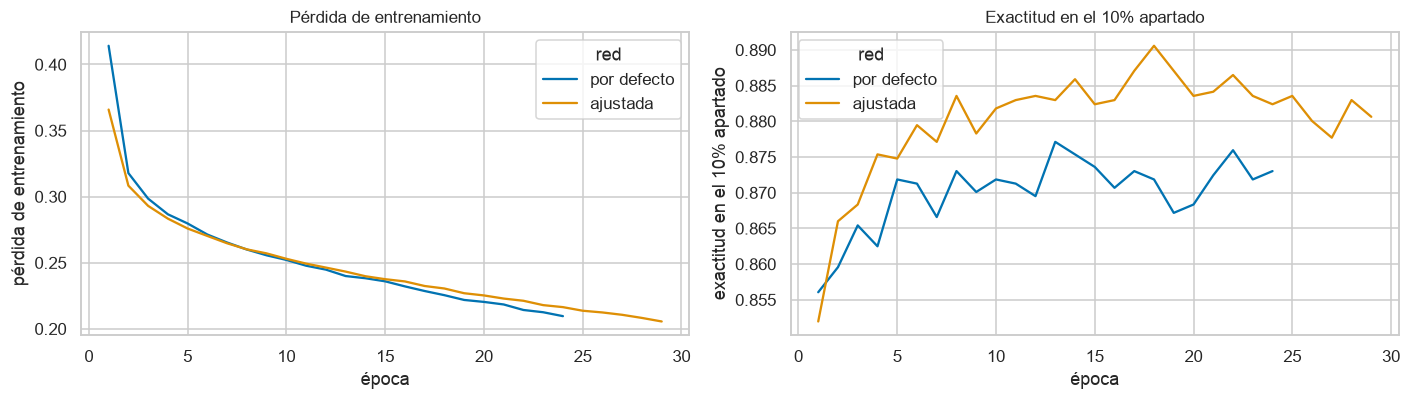

In [15]:
curve_rows = []
for label, model in (("por defecto", CANDIDATES["Red neuronal (MLP)"]), ("ajustada", MLP_TUNED)):
    net = clone(model).fit(X[train], y[train])
    curve_rows += [{"red": label, "época": e + 1, "pérdida de entrenamiento": loss, "exactitud en el 10% apartado": score}
                   for e, (loss, score) in enumerate(zip(net.loss_curve_, net.validation_scores_))]
    print(f"Red {label}: {net.n_iter_} épocas; mejor exactitud en el 10% apartado {net.best_validation_score_:.4f}")
curves = pd.DataFrame(curve_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, column in zip(axes, ["pérdida de entrenamiento", "exactitud en el 10% apartado"]):
    sns.lineplot(data=curves, x="época", y=column, hue="red", ax=ax)
    ax.set(title=column.capitalize())
plt.tight_layout()
plt.show()

La red ajustada avanza con pasos más pequeños, entrena más épocas (29 contra 24) y logra mejor exactitud en los ECG que aparta para la parada temprana

### Resumen de la búsqueda

La tabla muestra cuántas configuraciones probamos y cuánto tardó cada etapa. Cada configuración se entrena ocho veces, una por pliegue.

In [16]:
search_log = pd.DataFrame(SEARCH_LOG)
display(search_log.round(4).set_index(["modelo", "etapa"]))
display(search_log.groupby("modelo")[["configuraciones", "entrenamientos", "minutos"]].sum().round(1))

configuraciones  entrenamientos  \
modelo       etapa                                                              
SVM          1. kernel                                      6              48   
             2. malla de C y gamma                         24             192   
             3. malla fina                                 10              80   
Red neuronal 1. búsqueda aleatoria                         60             480   
             2a. alpha y tasa de aprendizaje                9              72   
             2b. arquitectura y activación                 27             216   
             3. semillas, por defecto                       5              40   
             3. semillas, ajustada                          5              40   

                                              minutos  mejor AUROC (VC)  
modelo       etapa                                                       
SVM          1. kernel                         4.0966            0.9509  
             2. malla de C y gamma            20.7654            0.9509  
             3. malla fina                     8.5191            0.9511  
Red neuronal 1. búsqueda aleatoria            10.0842            0.9490  
             2a. alpha y tasa de aprendizaje   0.6531            0.9490  
             2b. arquitectura y activación     3.9091            0.9490  
             3. semillas, por defecto          0.1952            0.9488  
             3. semillas, ajustada             0.3036            0.9494

,configuraciones,entrenamientos,minutos
modelo,,,
Red neuronal,106,848,15.1
SVM,40,320,33.4


## 7. Comparación de los dos modelos ajustados

Comparamos las versiones ajustadas con sus versiones por defecto y con el baseline en el pliegue 9 porque no participó en ninguna búsqueda.

In [17]:
tuned_rows = [evaluate("SVM ajustada", SVM_TUNED), evaluate("Red neuronal ajustada", MLP_TUNED),
              evaluate("Gradient boosting (ensamble, solo referencia)", HistGradientBoostingClassifier(random_state=SEED))]
TUNED_ORDER = ["Regresión logística (baseline)", "SVM con kernel RBF", "SVM ajustada", "Red neuronal (MLP)", "Red neuronal ajustada", "Gradient boosting (ensamble, solo referencia)"]
tuned = pd.concat([comparison.drop(columns="puesto"), pd.DataFrame(tuned_rows).set_index("modelo")]).loc[TUNED_ORDER]
tuned.index = ["Regresión logística (baseline)", "SVM por defecto", "SVM ajustada", "Red neuronal por defecto", "Red neuronal ajustada", "Gradient boosting (ensamble, solo referencia)"]
RESULTS["SVM por defecto"], RESULTS["Red neuronal por defecto"] = RESULTS["SVM con kernel RBF"], RESULTS["Red neuronal (MLP)"]
display(tuned[[c for c in COLUMNS if c != "puesto"]].rename(columns=COLUMNS).round(DIGITS))

,AUROC (VC),desv. entre pliegues,AUROC pliegue 9,sens. con esp. 90%,esp. con sens. 95%,AUPRC,entrenamiento (s),"predicción (ms por 1,000 ECG)"
Regresión logística (baseline),0.9353,0.0040,0.9280,0.826,0.620,0.957,0.08,0.8
SVM por defecto,0.9509,0.0043,0.9399,0.861,0.712,0.967,3.26,362.2
SVM ajustada,0.9511,0.0044,0.9393,0.864,0.706,0.967,3.66,383.6
Red neuronal por defecto,0.9484,0.0045,0.9356,0.852,0.689,0.965,0.53,1.0
Red neuronal ajustada,0.9490,0.0039,0.9404,0.860,0.688,0.966,1.48,1.4
"Gradient boosting (ensamble, solo referencia)",0.9549,0.0041,0.9430,0.868,0.740,0.969,1.07,5.9


Como la SVM y la red empatan en AUROC, revisamos aspectos que importan para el uso real del modelo. Primero aplicamos al pliegue 9 los dos umbrales del Avance 3:

In [19]:
def operating_thresholds(score_train: np.ndarray) -> dict[str, float]:
    return {"derivación del 10% de normales": float(np.quantile(score_train[Y_TRAIN == 0], 0.90)),
            "95% de sensibilidad": float(np.quantile(score_train[Y_TRAIN == 1], 0.05))}


FINALISTS = ["Regresión logística (baseline)", "SVM ajustada", "Red neuronal ajustada"]
point_rows = []
for name in FINALISTS:
    for point, threshold in operating_thresholds(RESULTS[name]["oof"]).items():
        m = metric_intervals(Y_VAL, RESULTS[name]["val"], PATIENTS_VAL, threshold)["metrics"]
        point_rows.append({"modelo": name, "umbral fijado en entrenamiento": point,
                           **{label: f"{m[key]['value']:.3f} [{m[key]['ci_low']:.3f}, {m[key]['ci_high']:.3f}]" for key, label in (("sensitivity", "sensibilidad"), ("specificity", "especificidad"))}})
display(pd.DataFrame(point_rows).set_index(["umbral fijado en entrenamiento", "modelo"]).sort_index(level=0, sort_remaining=False))

sensibilidad  \
umbral fijado en entrenamiento modelo                                                 
95% de sensibilidad            Regresión logística (baseline)  0.924 [0.909, 0.939]   
                               SVM ajustada                    0.930 [0.916, 0.944]   
                               Red neuronal ajustada           0.928 [0.913, 0.942]   
derivación del 10% de normales Regresión logística (baseline)  0.791 [0.768, 0.814]   
                               SVM ajustada                    0.828 [0.806, 0.850]   
                               Red neuronal ajustada           0.821 [0.800, 0.843]   

                                                                      especificidad  
umbral fijado en entrenamiento modelo                                                
95% de sensibilidad            Regresión logística (baseline)  0.654 [0.623, 0.686]  
                               SVM ajustada                    0.731 [0.701, 0.761]  
                               Red neuronal ajustada           0.731 [0.701, 0.761]  
derivación del 10% de normales Regresión logística (baseline)  0.910 [0.891, 0.928]  
                               SVM ajustada                    0.902 [0.882, 0.921]  
                               Red neuronal ajustada           0.910 [0.891, 0.927]

Después, el desempeño con menos ECG etiquetados. El dataset real que usaremos con la universidad de Italia tendrá unos 2,000 ECG etiquetados, muchos menos que los 17,083 de PTB-XL, así que entrenamos cada modelo con fracciones del entrenamiento, desde unos 750 ECG.

Curvas de aprendizaje en 82 s


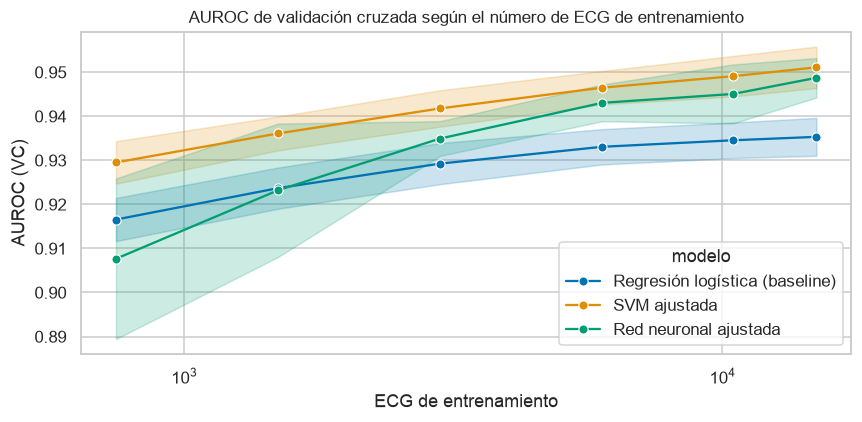

modelo,Red neuronal ajustada,Regresión logística (baseline),SVM ajustada
ECG de entrenamiento,,,
747,0.9077,0.9166,0.9295
1494,0.9232,0.9237,0.9361
2988,0.9349,0.9293,0.9418
5977,0.9430,0.9331,0.9465
10460,0.9451,0.9345,0.9491
14944,0.9487,0.9353,0.9511


In [20]:
SIZES = [0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
start = time.perf_counter()
learning_rows = []
for name, model in (("Regresión logística (baseline)", LogisticRegression(C=0.1, max_iter=5000)), ("SVM ajustada", SVM_TUNED), ("Red neuronal ajustada", MLP_TUNED)):
    sizes, _, cv_scores = learning_curve(model, X[train], y[train], cv=CV, scoring="roc_auc", train_sizes=SIZES, shuffle=True, random_state=SEED, n_jobs=N_JOBS)
    learning_rows += [{"modelo": name, "ECG de entrenamiento": int(s), "AUROC (VC)": a} for s, row in zip(sizes, cv_scores) for a in row]
learning = pd.DataFrame(learning_rows)
print(f"Curvas de aprendizaje en {time.perf_counter() - start:.0f} s")
fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=learning, x="ECG de entrenamiento", y="AUROC (VC)", hue="modelo", marker="o", errorbar="sd", ax=ax)
ax.set(xscale="log", title="AUROC de validación cruzada según el número de ECG de entrenamiento")
plt.tight_layout()
plt.show()
display(learning.groupby(["ECG de entrenamiento", "modelo"])["AUROC (VC)"].mean().unstack().round(4))

Desordenamos cada familia de características en el pliegue 9 y medimos cuánto baja el AUROC.

Permutación por familia en 70 s


modelo,Regresión logística (baseline),SVM ajustada,Red neuronal ajustada
familia,,,
Repolarización (ST-T),0.2056,0.2157,0.2300
QRS: amplitud y eje,0.1273,0.1294,0.1250
Estadísticos de la señal,0.0237,0.0232,0.0283
Intervalos,0.0089,0.0073,0.0071
Ritmo,0.0028,0.0001,0.0013
Espectro,0.0010,0.0010,0.0011
Onda P,0.0001,0.0004,0.0003
Calidad,-0.0001,0.0004,0.0002


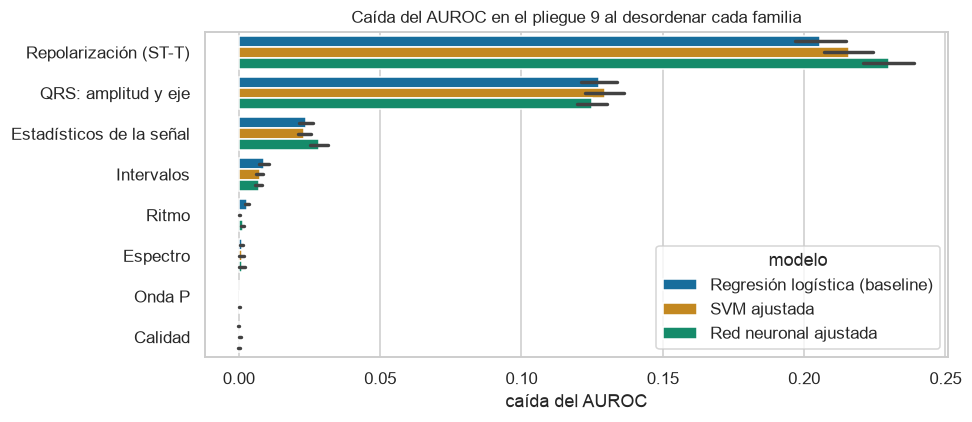

In [21]:
def family_permutation(name: str, repeats: int = 10) -> list[dict]:
    model, rng = RESULTS[name]["model"], np.random.default_rng(SEED)
    base = roc_auc_score(Y_VAL, RESULTS[name]["val"])
    rows = []
    for family in FAMILIES:
        columns = list(FAMILY.index[FAMILY == family])
        for _ in range(repeats):
            shuffled = X[val].copy()
            shuffled[columns] = X[val][columns].to_numpy()[rng.permutation(len(shuffled))]
            rows.append({"modelo": name, "familia": family, "caída del AUROC": base - roc_auc_score(Y_VAL, scores_of(model, shuffled))})
    return rows


start = time.perf_counter()
importance = pd.DataFrame([row for name in FINALISTS for row in family_permutation(name)])
print(f"Permutación por familia en {time.perf_counter() - start:.0f} s")
importance_table = importance.groupby(["familia", "modelo"])["caída del AUROC"].mean().unstack()[FINALISTS].sort_values("Regresión logística (baseline)", ascending=False)
display(importance_table.round(4))
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=importance, y="familia", x="caída del AUROC", hue="modelo", order=list(importance_table.index), errorbar="sd", ax=ax)
ax.set(title="Caída del AUROC en el pliegue 9 al desordenar cada familia", ylabel="")
plt.tight_layout()
plt.show()

Por ultimo, vemoslo que guarda cada modelo, cuánto tarda, si entrega una probabilidad y si su resultado cambia con la semilla.

In [22]:
def model_size(name: str) -> dict:
    model = RESULTS[name]["model"]
    if isinstance(model, SVC):
        stored = f"{model.support_vectors_.shape[0]:,} vectores de soporte × 111 características"
    elif isinstance(model, MLPClassifier):
        stored = f"{sum(w.size for w in model.coefs_) + sum(b.size for b in model.intercepts_):,} pesos"
    else:
        stored = f"{model.coef_.size + model.intercept_.size} coeficientes"
    return {"lo que guarda": stored, "archivo (KB)": round(len(pickle.dumps(model)) / 1e3, 1)}


profile = pd.DataFrame({name: {**model_size(name), "entrenamiento (s)": round(tuned.loc[name, "entrenamiento_s"], 2),
                               "predicción (ms por 1,000 ECG)": round(tuned.loc[name, "prediccion_ms_por_1000"], 1),
                               "entrega probabilidad": "sí" if hasattr(RESULTS[name]["model"], "predict_proba") else "no"} for name in FINALISTS}).T
profile["desv. entre semillas"] = "no aplica (determinista)"
profile.loc["Red neuronal ajustada", "desv. entre semillas"] = f"{seeds.loc[seeds['configuración'] == 'ajustada', 'AUROC (VC)'].std():.4f}"
display(profile)

,lo que guarda,archivo (KB),entrenamiento (s),"predicción (ms por 1,000 ECG)",entrega probabilidad,desv. entre semillas
Regresión logística (baseline),112 coeficientes,3.1,0.08,0.8,sí,no aplica (determinista)
SVM ajustada,"5,471 vectores de soporte × 111 características",4970.5,3.66,383.6,no,no aplica (determinista)
Red neuronal ajustada,"14,465 pesos",356.7,1.48,1.4,sí,0.0004


## 8. Elección del modelo individual final

Los dos modelos empatan en AUROC, así que decidimos con los demás criterios:

| Criterio | SVM ajustada | Red neuronal ajustada | Ventaja |
| --- | --- | --- | --- |
| AUROC en validación cruzada | 0.9511 (mejor en 7 de 8 pliegues) | 0.9490 | SVM, por poco |
| AUROC en el pliegue 9 | 0.9393 | 0.9404 | Empate |
| Especificidad con el umbral de 95% de sensibilidad (pliegue 9) | 0.731 | 0.731 | Empate |
| AUROC con 1,494 y 2,988 ECG de entrenamiento (alrededor de los 2,000 del dataset real) | 0.936 y 0.942 | 0.923 y 0.935 | SVM |
| Reproducibilidad | Determinista | Cambia con la semilla (desviación de 0.0004) | SVM |
| Costo de predicción | 384 ms por 1,000 ECG; archivo de 5 MB | 1.4 ms por 1,000 ECG; archivo de 357 KB | Red |
| Probabilidad | No la entrega directamente | Sí | Red |
| Interpretabilidad | Sin coeficientes; usa las mismas familias que el baseline | Igual | Empate |

Elegimos la SVM con kernel RBF ajustada (`C = 3`, `gamma = 0.0056`) por tres razones:

1. Rinde mejor con la cantidad de datos etiquetados aproximados que tendremos (aprox. 2000)
2. No depende del ajuste. Su configuración por defecto ya era óptima, así que se puede reentrenar con datos nuevos sin repetir una búsqueda larga.
3. Es determinista: los mismos datos dan siempre el mismo modelo, lo que facilita auditarlo.

In [23]:
FINAL_NAME = "SVM ajustada"
RUNNER_UP = "Red neuronal ajustada"
FINAL_MODEL = {"SVM ajustada": SVM_TUNED, "Red neuronal ajustada": MLP_TUNED}[FINAL_NAME]
print(f"Modelo final: {FINAL_NAME} | {repr(FINAL_MODEL)}")

Modelo final: SVM ajustada | SVC(C=3, gamma=0.0056, random_state=42)


## 9. Verificación en el pliegue de prueba

Con la elección tomada, evaluamos una sola vez en el pliegue 10 el modelo final y el baseline. La red neuronal y el gradient boosting aparecen solo como información; no cambian la elección.

In [24]:
def patient_bootstrap(statistic, *arrays: np.ndarray, patient_ids: np.ndarray, draws: int = 2000) -> tuple[float, float]:
    rng = np.random.default_rng(SEED)
    groups = patient_groups(patient_ids)
    values = [statistic(*(a[rows] for a in arrays)) for rows in (patient_resample(groups, rng) for _ in range(draws))]
    low, high = np.percentile(values, [2.5, 97.5])
    return float(low), float(high)


COMPARED = ["Regresión logística (baseline)", FINAL_NAME, RUNNER_UP, "Gradient boosting (ensamble, solo referencia)"]
y_test, patients_test = y[test].to_numpy(), patients[test.to_numpy()]
test_scores = {name: scores_of(RESULTS[name]["model"], X[test]) for name in COMPARED}

ranking_rows, test_points = [], []
for name in COMPARED:
    score = test_scores[name]
    spec95_low, spec95_high = patient_bootstrap(specificity_at_sensitivity, y_test, score, patient_ids=patients_test)
    for point, threshold in operating_thresholds(RESULTS[name]["oof"]).items():
        m = metric_intervals(y_test, score, patients_test, threshold)["metrics"]
        test_points.append({"modelo": name, "umbral fijado en entrenamiento": point,
                            **{label: f"{m[key]['value']:.3f} [{m[key]['ci_low']:.3f}, {m[key]['ci_high']:.3f}]" for key, label in (("sensitivity", "sensibilidad"), ("specificity", "especificidad"))}})
    ranking_rows.append({"modelo": name, "AUROC": f"{m['auroc']['value']:.3f} [{m['auroc']['ci_low']:.3f}, {m['auroc']['ci_high']:.3f}]",
                         "AUPRC": f"{m['average_precision']['value']:.3f} [{m['average_precision']['ci_low']:.3f}, {m['average_precision']['ci_high']:.3f}]",
                         "esp. con sens. 95%": f"{specificity_at_sensitivity(y_test, score):.3f} [{spec95_low:.3f}, {spec95_high:.3f}]"})
print("Métricas sin umbral en el pliegue 10 (IC 95% por bootstrap de pacientes):")
display(pd.DataFrame(ranking_rows).set_index("modelo"))
print("Puntos de operación con el umbral fijado en entrenamiento, aplicados al pliegue 10:")
display(pd.DataFrame(test_points).set_index(["umbral fijado en entrenamiento", "modelo"]).sort_index(level=0, sort_remaining=False))
versus_baseline = paired_auroc_difference(patients_test, y_test, test_scores[FINAL_NAME], test_scores["Regresión logística (baseline)"])
versus_runner_up = paired_auroc_difference(patients_test, y_test, test_scores[FINAL_NAME], test_scores[RUNNER_UP])
for label, diff in ((f"{FINAL_NAME} menos baseline", versus_baseline), (f"{FINAL_NAME} menos {RUNNER_UP}", versus_runner_up)):
    print(f"AUROC {label} en prueba: {diff['difference']:+.4f}, IC 95% [{diff['ci_low']:+.4f}, {diff['ci_high']:+.4f}]")

Métricas sin umbral en el pliegue 10 (IC 95% por bootstrap de pacientes):


,AUROC,AUPRC,esp. con sens. 95%
modelo,,,
Regresión logística (baseline),"0.917 [0.905, 0.929]","0.946 [0.937, 0.955]","0.536 [0.439, 0.591]"
SVM ajustada,"0.933 [0.923, 0.944]","0.956 [0.948, 0.964]","0.618 [0.542, 0.667]"
Red neuronal ajustada,"0.933 [0.922, 0.943]","0.956 [0.948, 0.963]","0.589 [0.507, 0.652]"
"Gradient boosting (ensamble, solo referencia)","0.937 [0.927, 0.947]","0.959 [0.951, 0.966]","0.622 [0.556, 0.683]"


Puntos de operación con el umbral fijado en entrenamiento, aplicados al pliegue 10:


sensibilidad  \
umbral fijado en entrenamiento modelo                                                                
95% de sensibilidad            Regresión logística (baseline)                 0.916 [0.900, 0.931]   
                               SVM ajustada                                   0.917 [0.901, 0.932]   
                               Red neuronal ajustada                          0.917 [0.901, 0.933]   
                               Gradient boosting (ensamble, solo referencia)  0.913 [0.896, 0.928]   
derivación del 10% de normales Regresión logística (baseline)                 0.773 [0.748, 0.798]   
                               SVM ajustada                                   0.808 [0.786, 0.831]   
                               Red neuronal ajustada                          0.803 [0.779, 0.826]   
                               Gradient boosting (ensamble, solo referencia)  0.824 [0.803, 0.847]   

                                                                                     especificidad  
umbral fijado en entrenamiento modelo                                                               
95% de sensibilidad            Regresión logística (baseline)                 0.640 [0.609, 0.673]  
                               SVM ajustada                                   0.719 [0.689, 0.749]  
                               Red neuronal ajustada                          0.726 [0.696, 0.755]  
                               Gradient boosting (ensamble, solo referencia)  0.747 [0.718, 0.776]  
derivación del 10% de normales Regresión logística (baseline)                 0.907 [0.887, 0.925]  
                               SVM ajustada                                   0.902 [0.883, 0.921]  
                               Red neuronal ajustada                          0.907 [0.887, 0.926]  
                               Gradient boosting (ensamble, solo referencia)  0.910 [0.891, 0.928]

AUROC SVM ajustada menos baseline en prueba: +0.0164, IC 95% [+0.0106, +0.0226]
AUROC SVM ajustada menos Red neuronal ajustada en prueba: +0.0009, IC 95% [-0.0022, +0.0041]


El AUROC baja de la validación cruzada (0.951) a la prueba (0.933), pero baja igual en el baseline y en el gradient boosting, así que se debe a que el pliegue 10 es más difícil y no a un sobreajuste.

### Las cinco superclases y el benchmark

Para compararnos con la literatura, entrenamos un modelo por superclase y calculamos el AUROC macro en el pliegue 10, como en el benchmark de Strodthoff et al. (2021).

Diez modelos por superclase en 42 s


,NORM,MI,STTC,CD,HYP,macro
Regresión logística (baseline),0.924,0.888,0.917,0.886,0.876,0.898
SVM ajustada,0.940,0.924,0.930,0.905,0.894,0.919


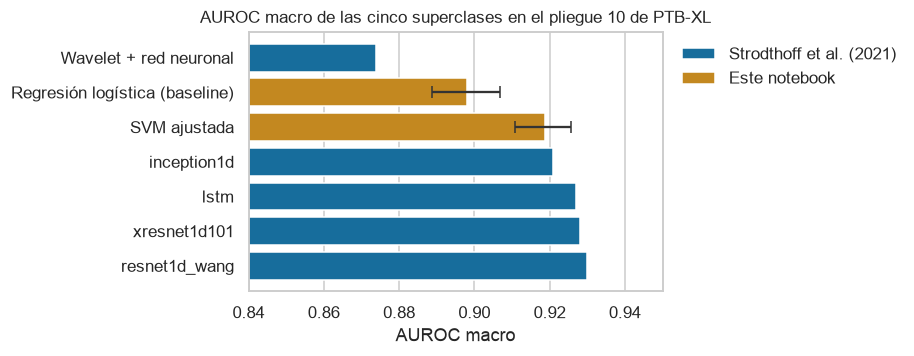

,AUROC macro,inferior,superior
modelo,,,
Regresión logística (baseline),0.898,0.889,0.907
SVM ajustada,0.919,0.911,0.926


In [25]:
labels_test = data.loc[test, SUPERCLASSES].to_numpy()


def superclass_matrix(model) -> np.ndarray:
    return np.column_stack([scores_of(clone(model).fit(X[train], data.loc[train, name]), X[test]) for name in SUPERCLASSES])


def macro_auroc(labels: np.ndarray, scores: np.ndarray) -> float:
    return float(np.mean([roc_auc_score(labels[:, i], scores[:, i]) for i in range(labels.shape[1])]))


start = time.perf_counter()
superclass_rows, macro_rows = {}, []
for name, model in (("Regresión logística (baseline)", LogisticRegression(C=0.1, max_iter=5000)), (FINAL_NAME, FINAL_MODEL)):
    matrix = superclass_matrix(model)
    superclass_rows[name] = {s: roc_auc_score(labels_test[:, i], matrix[:, i]) for i, s in enumerate(SUPERCLASSES)} | {"macro": macro_auroc(labels_test, matrix)}
    low, high = patient_bootstrap(macro_auroc, labels_test, matrix, patient_ids=patients_test)
    macro_rows.append({"modelo": name, "AUROC macro": superclass_rows[name]["macro"], "inferior": low, "superior": high})
print(f"Diez modelos por superclase en {time.perf_counter() - start:.0f} s")
display(pd.DataFrame(superclass_rows).T.round(3))

BENCHMARK = {"Wavelet + red neuronal": 0.874, "inception1d": 0.921, "lstm": 0.927, "xresnet1d101": 0.928, "resnet1d_wang": 0.930}
reference = pd.concat([pd.DataFrame({"modelo": list(BENCHMARK), "AUROC macro": list(BENCHMARK.values()), "origen": "Strodthoff et al. (2021)"}),
                       pd.DataFrame(macro_rows).assign(origen="Este notebook")]).sort_values("AUROC macro").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 3.4))
sns.barplot(data=reference, x="AUROC macro", y="modelo", hue="origen", dodge=False, ax=ax)
for i, row in reference.dropna(subset=["inferior"]).iterrows():
    ax.errorbar(row["AUROC macro"], i, xerr=[[row["AUROC macro"] - row.inferior], [row.superior - row["AUROC macro"]]], color="0.2", capsize=4)
ax.set(xlim=(0.84, 0.95), ylabel="", title="AUROC macro de las cinco superclases en el pliegue 10 de PTB-XL")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.01, 1), title="", frameon=False)
plt.tight_layout()
plt.show()
display(pd.DataFrame(macro_rows).set_index("modelo").round(3))

La SVM mejora al baseline en las cinco superclases

## 10. Archivos del avance

Guardamos el modelo final, sus umbrales y las tablas de resultados.

In [26]:
FINAL_PARAMS = SVM_PARAMS if FINAL_NAME == "SVM ajustada" else MLP_PARAMS
joblib.dump({"model": RESULTS[FINAL_NAME]["model"], "features": FEATURES, "params": FINAL_PARAMS, "thresholds": operating_thresholds(RESULTS[FINAL_NAME]["oof"])},
            OUT / "modelo_final.joblib")
comparison.to_csv(OUT / "comparativa_siete_modelos.csv")
tuned.to_csv(OUT / "comparativa_modelos_ajustados.csv")
search_log.to_csv(OUT / "resumen_busqueda.csv", index=False)
for stem, table in (("busqueda_svm_kernel", svm_kernel_table), ("busqueda_svm_malla", svm_grid_table), ("busqueda_svm_fina", svm_fine_table),
                    ("busqueda_mlp_aleatoria", mlp_random_table), ("busqueda_mlp_alpha_tasa", mlp_refine_table), ("busqueda_mlp_arquitectura", mlp_arch_table)):
    table.drop(columns="params").to_csv(OUT / f"{stem}.csv", index=False)
summary = {
    "dataset": "PTB-XL 1.0.3", "entrada": to_stored(TABLE) if TABLE.is_relative_to(ROOT) else TABLE.name, "python": platform.python_version(), "versiones": VERSIONS,
    "particion": {"train": "pliegues 1-8", "val": "pliegue 9", "test": "pliegue 10"},
    "modelo_final": FINAL_NAME, "parametros": FINAL_PARAMS,
    "segundo_lugar": RUNNER_UP, "umbrales": operating_thresholds(RESULTS[FINAL_NAME]["oof"]),
    "validacion_cruzada": {"AUROC": tuned.loc[FINAL_NAME, "AUROC"], **summarize(Y_TRAIN, RESULTS[FINAL_NAME]["oof"])},
    "validacion": {"AUROC": tuned.loc[FINAL_NAME, "AUROC_pliegue_9"], **summarize(Y_VAL, RESULTS[FINAL_NAME]["val"])},
    "prueba": {"AUROC": roc_auc_score(y_test, test_scores[FINAL_NAME]), **summarize(y_test, test_scores[FINAL_NAME]),
               "diferencia_auroc_vs_baseline": versus_baseline, "auroc_superclases": superclass_rows[FINAL_NAME]},
}
(OUT / "resumen.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=lambda o: o.item() if isinstance(o, np.generic) else str(o)))
display(pd.DataFrame([{"archivo": f.name, "KB": round(f.stat().st_size / 1e3, 1)} for f in sorted(OUT.iterdir())]).set_index("archivo"))
print(f"Notebook completo en {(time.perf_counter() - NOTEBOOK_START) / 60:.1f} min")

,KB
archivo,
busqueda_mlp_aleatoria.csv,34.4
busqueda_mlp_alpha_tasa.csv,5.0
busqueda_mlp_arquitectura.csv,14.5
busqueda_svm_fina.csv,5.3
busqueda_svm_kernel.csv,3.3
busqueda_svm_malla.csv,12.5
comparativa_modelos_ajustados.csv,1.2
comparativa_siete_modelos.csv,1.3
modelo_final.joblib,4972.6


Notebook completo en 56.1 min


Tres hallazgos importan para despues:

- Más búsqueda de hiperparámetros difícilmente mejorará a estos modelos. Las dos búsquedas encontraron mesetas: en la malla fina de la SVM, ocho de diez combinaciones quedan a menos de 0.0012 del máximo, y las diez mejores configuraciones de la red están a menos de 0.002 de la mejor.

- El gradient boosting, un ensamble, sigue arriba en validación cruzada (0.955 contra 0.951), aunque en el pliegue 9 su ventaja ya no es concluyente y en prueba queda 0.004 arriba. Combinar modelos puede valer la pena, pero la ganancia esperada es pequeña.

- El umbral de 95% de sensibilidad fijado en entrenamiento sigue sin trasladarse completo a ECG nuevos (0.917 en prueba). Si el servicio necesita garantizar una sensibilidad, el umbral tendrá que fijarse o revisarse con datos de la población donde se use.

## 12. Declaración del uso de inteligencia artificial

### Uso de herramientas de IA

| Herramienta utilizada | Propósito de uso | Alcance del apoyo (celdas o secciones) | Responsabilidad: qué revisó o validó el equipo |
|---|---|---|---|
| Anthropic. (2026). Claude Code (Claude Opus 5.5) [Modelo de lenguaje grande].<br>https://claude.com/claude-code | Revision y corrección de texto y código, además de añadir gráficas para una mejor visualización | Secciones 1 a 11 | Cada integrante revisó el código y verificó los resultados de las secciones a su cargo (ver contribución individual). |

### Contribución individual

| Integrante | Contribución al avance |
|---|---|
| Clara Janet Rivera Medina | Responsable de la arquitectura empleada y las métricas elegidas |
| José Emiliano Luna López | Responsable de la evaluación y la elección del modelo final |
| Andre Nicolai Gutierrez Bautista | Responsable del ajuste fino de hiperparámetros |

### Decisiones principales

<small><b>Decisión 1:</b> Dejar fuera de la competencia al gradient boosting y al bosque aleatorio.</small>

- <small>Justificación: el avance pide modelos individuales, y Géron (2022, cap. 7) clasifica a los dos como ensambles porque combinan cientos de árboles.</small>
- <small>Alternativa descartada y motivo: incluir el gradient boosting, que tiene el mayor AUROC de validación cruzada (0.955), porque no cumple la condición del avance. Se muestra solo como referencia.</small>

<small><b>Decisión 2:</b> Comparar los siete modelos con su configuración por defecto, revisar a los cinco últimos con un ajuste rápido y ajustar a fondo solo a los dos mejores.</small>

- <small>Justificación: concentra el cómputo de la búsqueda (146 configuraciones y 1,168 entrenamientos) en los dos modelos con posibilidades, y el ajuste rápido confirmó que ningún otro modelo alcanzaba a los dos primeros.</small>
- <small>Alternativa descartada y motivo: ajustar a fondo los siete modelos, que habría multiplicado el tiempo de ejecución sin cambiar la selección.</small>

<small><b>Decisión 3:</b> Elegir la SVM sobre la red neuronal aunque empatan en AUROC.</small>

- <small>Justificación: rinde mejor con unos 2,000 ECG etiquetados, la cantidad que tendrá el dataset real; no depende del ajuste de hiperparámetros y es determinista.</small>
- <small>Alternativa descartada y motivo: la red neuronal, más rápida y con probabilidades, porque con 1,500 ECG de entrenamiento o menos queda al nivel del baseline.</small>